In [1]:
print("hello")

hello


In [2]:
pip show shap

Name: shap
Version: 0.52.0
Summary: A unified approach to explain the output of any machine learning model.
Home-page: 
Author: 
Author-email: Scott Lundberg <slund1@cs.washington.edu>
License: MIT License
Location: C:\Users\loq\Desktop\fraud-detection\.venv\Lib\site-packages
Requires: cloudpickle, llvmlite, numba, numpy, packaging, pandas, scikit-learn, scipy, slicer, tqdm
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap

train = pd.read_csv("../donnees/processed/train.csv")
test = pd.read_csv("../donnees/processed/test.csv")

X_train = train.drop(columns="Class")
y_train = train["Class"]
X_test = test.drop(columns="Class")
y_test = test["Class"]

model = joblib.load("../models/model.joblib")

In [4]:
xgb_model = model.named_steps["model"]
print(type(xgb_model))

<class 'xgboost.sklearn.XGBClassifier'>


In [6]:
from sklearn.pipeline import Pipeline

preprocessing_pipeline = Pipeline(model.steps[:-1])
X_test_transformed = preprocessing_pipeline.transform(X_test)

In [8]:
from src.features import add_features

X_test_fe = add_features(X_test)
print(X_test_fe.columns.tolist())
print(len(X_test_fe.columns))

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Hour', 'is_night', 'log_amount']
32


In [9]:
numeric_features = ["log_amount", "Time", "Hour"]
remainder_features = [c for c in X_test_fe.columns if c not in numeric_features]

feature_names = numeric_features + remainder_features
print(len(feature_names))
print(feature_names)

32
['log_amount', 'Time', 'Hour', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'is_night']


In [10]:
print("Nombre de noms construits :", len(feature_names))
print("Nombre de colonnes dans X_test_transformed :", X_test_transformed.shape[1])

Nombre de noms construits : 32
Nombre de colonnes dans X_test_transformed : 32


In [11]:
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)
print(X_test_transformed_df.shape)
X_test_transformed_df.head()

(56962, 32)


,log_amount,Time,Hour,V1,V2,V3,V4,V5,V6,V7,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,is_night
0,0.015094,1.387182,1.020452,-0.674466,1.408105,-1.110622,-1.328366,1.388996,-1.308439,1.885879,...,0.394322,0.080084,0.810034,-0.224327,0.707899,-0.135837,0.045102,0.533837,0.291319,0.0
1,-0.362148,-1.580138,-1.552127,-2.829816,-2.765149,2.537793,-1.074580,2.842559,-2.153536,-1.795519,...,-0.515765,-0.295555,0.109305,-0.813272,0.042996,-0.027660,-0.910247,0.110802,-0.511938,1.0
2,0.719602,-0.138120,-2.409653,-3.576495,2.318422,1.306985,3.263665,1.127818,2.865246,1.444125,...,2.034786,-1.060151,0.016867,-0.132058,-1.483996,-0.296011,0.062823,0.552411,0.509764,1.0
3,-1.488488,0.986536,0.162926,2.060386,-0.015382,-1.082544,0.386019,-0.024331,-1.074935,0.207792,...,-0.192024,-0.281684,-0.639426,0.331818,-0.067584,-0.283675,0.203529,-0.063621,-0.060077,0.0
4,-1.350712,-1.182272,-0.694601,1.209965,1.384303,-1.343531,1.763636,0.662351,-2.113384,0.854039,...,0.009083,-0.164015,-0.328294,-0.154631,0.619449,0.818998,-0.330525,0.046884,0.104527,0.0


In [12]:
xgb_model = model.named_steps["model"]
print(type(xgb_model))

explainer = shap.TreeExplainer(xgb_model)

sample_size = 2000
X_sample = X_test_transformed_df.sample(sample_size, random_state=42)

shap_values = explainer.shap_values(X_sample)
print(shap_values.shape)

<class 'xgboost.sklearn.XGBClassifier'>
(2000, 32)


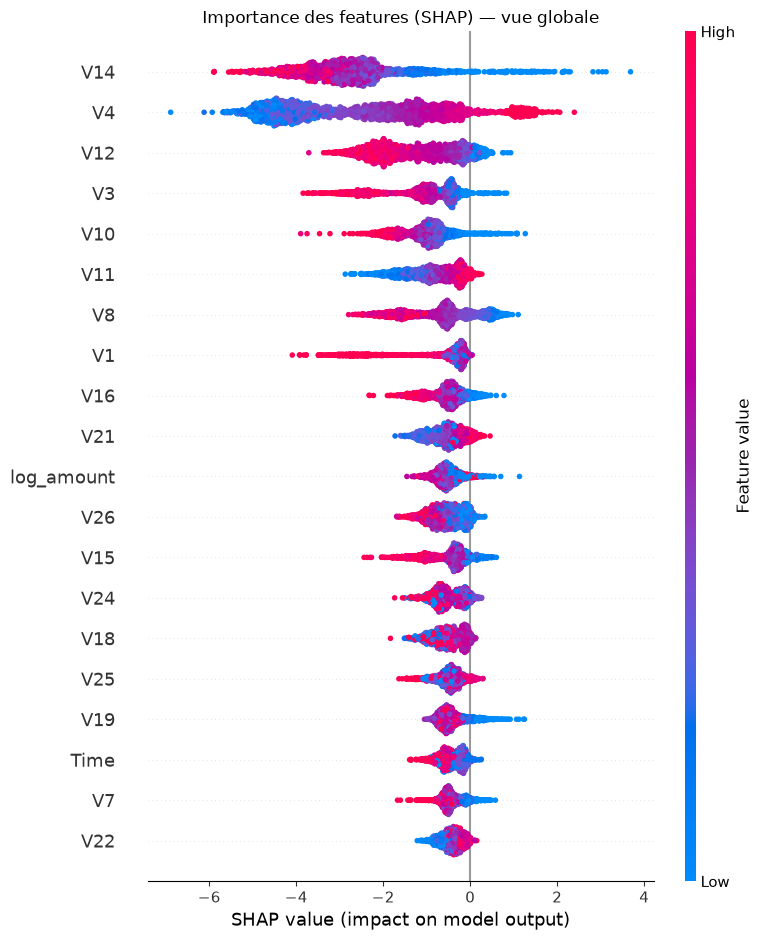

In [13]:
shap.summary_plot(shap_values, X_sample, show=False)
plt.title("Importance des features (SHAP) — vue globale")
plt.tight_layout()
plt.savefig("../models/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
sample_indices = X_sample.index
y_sample = y_test.loc[sample_indices]
proba_sample = model.predict_proba(X_test.loc[sample_indices])[:, 1]

fraud_mask = (y_sample == 1) & (proba_sample > 0.9)
if fraud_mask.sum() > 0:
    example_idx = X_sample[fraud_mask.values].index[0]
else:
    example_idx = X_sample[y_sample == 1].index[0]

position = list(X_sample.index).index(example_idx)
print("Probabilité de fraude prédite :", model.predict_proba(X_test.loc[[example_idx]])[:, 1][0])

Probabilité de fraude prédite : 0.99999654


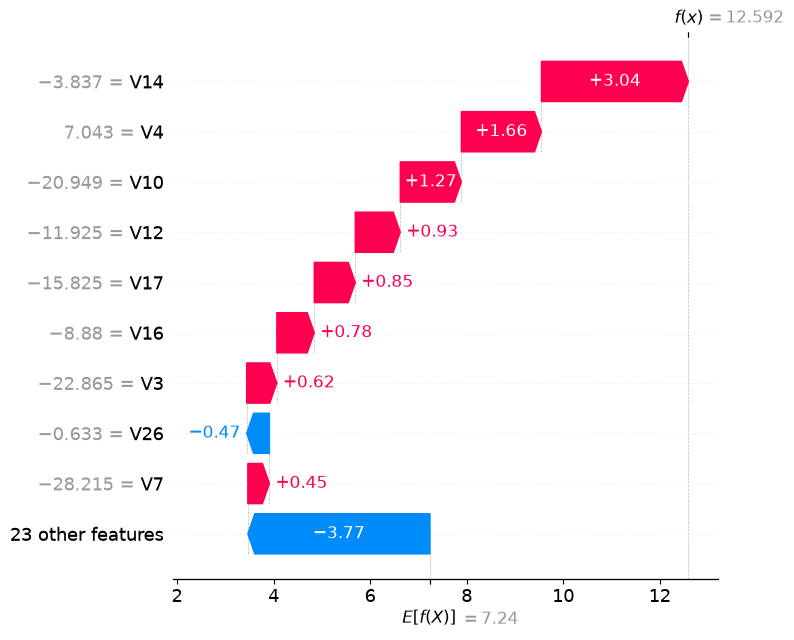

In [15]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[position],
        base_values=explainer.expected_value,
        data=X_sample.iloc[position],
        feature_names=X_sample.columns.tolist(),
    ),
    show=False
)
plt.tight_layout()
plt.savefig("../models/shap_waterfall_example.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
import os
print(os.listdir("../models"))

['model.joblib', 'shap_summary.png', 'shap_waterfall_example.png', 'threshold.json']
